# Практическое занятие №1-2. Парная линейная регрессия и градиентный спуск

**Цель работы:** познакомиться с моделью парной линейной регрессии и методом градиентного спуска.

**Содержание:** найти оценки параметров модели прямыми вычислениями и методом градиентного спуска, оценить качество модели, сравнив на графике обучающую выборку и прогнозы, построить кривые обучения.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Пример из занятия

Исходные данные: $x$ — расходы на рекламу, $Y$ — объёмы продаж.

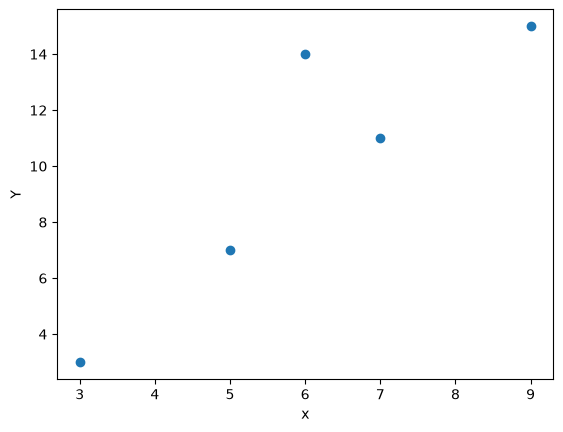

In [2]:
# float, иначе при целом alpha параметры модели останутся int64 и переполнятся
x = np.array([3, 5, 7, 6, 9], dtype=float)
Y = np.array([3, 7, 11, 14, 15], dtype=float)

plt.figure()
plt.scatter(x, Y)
plt.xlabel('x')
plt.ylabel('Y')
plt.show()

Оценки коэффициентов по формулам МНК:

$$a_1 = \frac{\overline{(x-\bar x)(Y-\bar Y)}}{\overline{(x-\bar x)^2}}, \qquad a_0 = \bar Y - a_1 \bar x$$

Модель линейной регрессии: Y^ = -2.0 + 2.0 * x


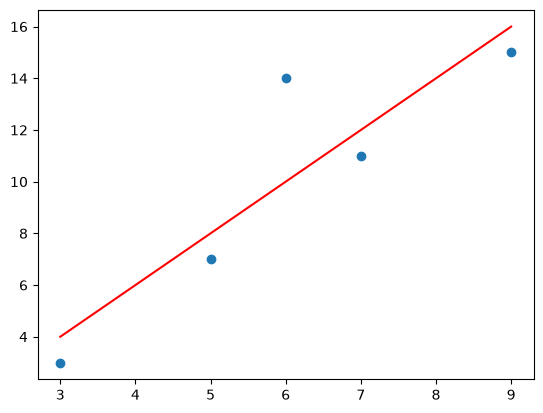

In [3]:
a1 = ((x - x.mean()) * (Y - Y.mean())).mean() / ((x - x.mean()) ** 2).mean()
a0 = Y.mean() - a1 * x.mean()
print('Модель линейной регрессии: Y^ =', a0, '+', a1, '* x')

x_space = np.linspace(3, 9, 7)
Y_pred = a0 + a1 * x_space

plt.figure()
plt.scatter(x, Y)
plt.plot(x_space, Y_pred, 'r')
plt.show()

Класс модели с циклом градиентного спуска и метриками MSE, MAE, MAPE.

In [4]:
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0

    def predict(self, x):
        return self.a0 + self.a1 * x

    def MSE(self, x, Y):
        return ((Y - self.predict(x)) ** 2).mean()

    def MAE(self, x, Y):
        return abs(Y - self.predict(x)).mean()

    def MAPE(self, x, Y):
        return abs((Y - self.predict(x)) / Y).mean()

    def fit(self, x, Y, alpha=0.001, epsilon=0.01, max_steps=5000):
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dT_a0 = -2 * sum(Y - self.predict(x))
            dT_a1 = -2 * sum((Y - self.predict(x)) * x)
            self.a0 -= alpha * dT_a0
            self.a1 -= alpha * dT_a1
            new_error = self.MSE(x, Y)
            step += 1
            steps.append(step)
            errors.append(new_error)
            if new_error < epsilon:
                break
        return steps, errors

a0 = -1.9831133883633372  a1 = 1.9974608002770196
MSE после градиентного спуска: 4.000028517306817


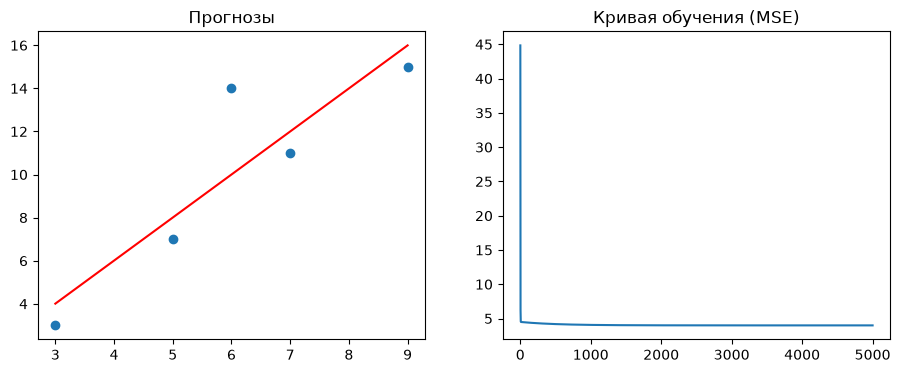

In [5]:
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha=0.001, epsilon=0.05)
print('a0 =', regr.a0, ' a1 =', regr.a1)
print('MSE после градиентного спуска:', regr.MSE(x, Y))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(x, Y)
ax[0].plot(x_space, regr.predict(x_space), 'r')
ax[0].set_title('Прогнозы')
ax[1].plot(steps, errors)
ax[1].set_title('Кривая обучения (MSE)')
plt.show()

### Эксперимент с параметрами градиентного спуска

Запустим цикл с разными скоростями обучения `alpha`, точностью `epsilon` и максимальным числом шагов `max_steps`.

In [6]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)  # переполнение при расходимости

rows = []
for alpha in [0.0001, 0.001, 0.005, 0.01, 0.1, 1, 10]:
    for epsilon in [0.001, 0.5, 5]:
        for max_steps in [100, 1000, 5000]:
            r = SimpleRegression()
            steps, errors = r.fit(x, Y, alpha=alpha, epsilon=epsilon, max_steps=max_steps)
            rows.append({'alpha': alpha, 'epsilon': epsilon, 'max_steps': max_steps,
                         'шагов': len(steps), 'MSE': r.MSE(x, Y), 'a0': r.a0, 'a1': r.a1})
pd.set_option('display.float_format', '{:.4g}'.format)
pd.set_option('display.max_rows', 100)
pd.DataFrame(rows)

,alpha,epsilon,max_steps,шагов,MSE,a0,a1
0,0.0001,0.001,100,100,4.524,0.2241,1.639
1,0.0001,0.001,1000,1000,4.416,0.04025,1.693
2,0.0001,0.001,5000,5000,4.19,-0.6203,1.793
3,0.0001,0.5,100,100,4.524,0.2241,1.639
4,0.0001,0.5,1000,1000,4.416,0.04025,1.693
5,0.0001,0.5,5000,5000,4.19,-0.6203,1.793
6,0.0001,5,100,66,4.966,0.2195,1.558
7,0.0001,5,1000,66,4.966,0.2195,1.558
8,0.0001,5,5000,66,4.966,0.2195,1.558
9,0.001,0.001,100,100,4.416,0.04016,1.693


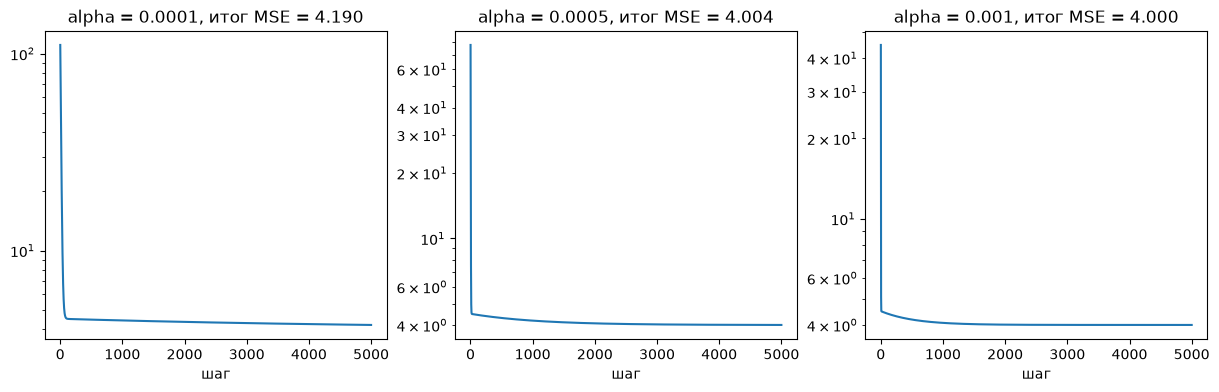

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, alpha in zip(axes, [0.0001, 0.0005, 0.001]):
    r = SimpleRegression()
    steps, errors = r.fit(x, Y, alpha=alpha, epsilon=0.001, max_steps=5000)
    ax.plot(steps, errors)
    ax.set_yscale('log')
    ax.set_title(f'alpha = {alpha}, итог MSE = {errors[-1]:.3f}')
    ax.set_xlabel('шаг')
plt.show()

**Вывод по эксперименту.**

- Минимально достижимое MSE на этих данных — 4.0 (при $a_0=-2,\ a_1=2$), поэтому `epsilon` < 4 никогда не достигается и спуск идёт до `max_steps`; `epsilon = 5` останавливает спуск рано (6–66 шагов) с недообученной моделью ($a_0 \approx 0.22$ вместо $-2$).
- Малая `alpha = 0.0001` сходится медленно: MSE быстро падает до ~4.5, но параметры и за 5000 шагов далеки от оптимума ($a_0 \approx -0.62$ вместо $-2$).
- `alpha = 0.001` — рабочее значение: за 5000 шагов сходится к аналитическому решению ($a_0 \approx -1.98,\ a_1 \approx 2.00$).
- При `alpha ≥ 0.005` шаг слишком большой: ошибка растёт на каждой итерации, процесс расходится (MSE → ∞/nan).

## 2. Задание: гиперспектр кукурузы

Загрузим файл `Гиперспектр кукурузы.csv`. В файле разделитель `;` и десятичная запятая, поэтому укажем это явно.

In [8]:
gipers = pd.read_csv('Гиперспектр кукурузы.csv', sep=';', decimal=',', encoding='utf-8-sig')
print(gipers.shape)
gipers.head()

(273, 2)


,wavelength,Spectr
0,397.3,0.02
1,399.5,0.03
2,401.8,0.03
3,404,0.05
4,406.2,0.05


In [9]:
gipers.describe()

,wavelength,Spectr
count,273,273
mean,699.2,0.2838
std,175.3,0.1774
min,397.3,0.02
25%,548.3,0.16
50%,699.2,0.19
75%,850.2,0.45
max,1001,0.62


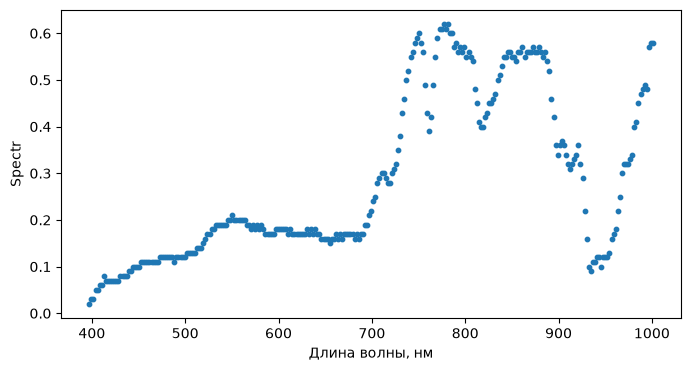

In [10]:
x = gipers['wavelength'].values
Y = gipers['Spectr'].values

plt.figure(figsize=(8, 4))
plt.scatter(x, Y, s=10)
plt.xlabel('Длина волны, нм')
plt.ylabel('Spectr')
plt.show()

### 2.1. Аналитическое решение

Модель линейной регрессии: Y^ = -0.183428 + 0.00066816 * x


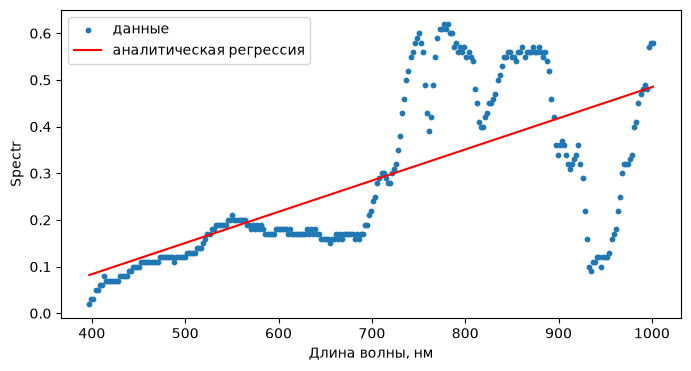

In [11]:
a1 = ((x - x.mean()) * (Y - Y.mean())).mean() / ((x - x.mean()) ** 2).mean()
a0 = Y.mean() - a1 * x.mean()
print(f'Модель линейной регрессии: Y^ = {a0:.6f} + {a1:.8f} * x')

analytic = SimpleRegression()
analytic.a0, analytic.a1 = a0, a1

x_space = np.linspace(x.min(), x.max(), 100)
plt.figure(figsize=(8, 4))
plt.scatter(x, Y, s=10, label='данные')
plt.plot(x_space, analytic.predict(x_space), 'r', label='аналитическая регрессия')
plt.xlabel('Длина волны, нм')
plt.ylabel('Spectr')
plt.legend()
plt.show()

### 2.2. Градиентный спуск

Если запустить спуск прямо на исходных данных, он расходится: $x \approx 400\ldots1000$, а в градиенте стоит сумма по 273 точкам от $x^2$, поэтому даже `alpha = 0.001` на порядки больше допустимого.

In [12]:
r = SimpleRegression()
steps, errors = r.fit(x, Y, alpha=0.001, epsilon=0.01, max_steps=10)
print('MSE по шагам:', [f'{e:.3g}' for e in errors])

MSE по шагам: ['7.42e+09', '5.97e+20', '4.8e+31', '3.87e+42', '3.11e+53', '2.5e+64', '2.01e+75', '1.62e+86', '1.3e+97', '1.05e+108']


Поэтому стандартизуем признак: $z = (x - \bar x) / \sigma_x$. На $z$ градиентный спуск сходится быстро, а коэффициенты для исходного $x$ восстанавливаются так:

$$Y = b_0 + b_1 z = \underbrace{\left(b_0 - b_1\frac{\bar x}{\sigma_x}\right)}_{a_0} + \underbrace{\frac{b_1}{\sigma_x}}_{a_1} x$$

Порог `epsilon` ставим чуть выше минимально возможного MSE, иначе он недостижим и спуск всегда идёт до `max_steps`.

In [13]:
z = (x - x.mean()) / x.std()

gd = SimpleRegression()
steps, errors = gd.fit(z, Y, alpha=0.001, epsilon=0.017685, max_steps=5000)
b0, b1 = gd.a0, gd.a1
gd.a0, gd.a1 = b0 - b1 * x.mean() / x.std(), b1 / x.std()
print('Шагов:', len(steps))
print(f'Градиентный спуск:  Y^ = {gd.a0:.6f} + {gd.a1:.8f} * x')
print(f'Аналитически:       Y^ = {a0:.6f} + {a1:.8f} * x')

Шагов: 8
Градиентный спуск:  Y^ = -0.183097 + 0.00066695 * x
Аналитически:       Y^ = -0.183428 + 0.00066816 * x


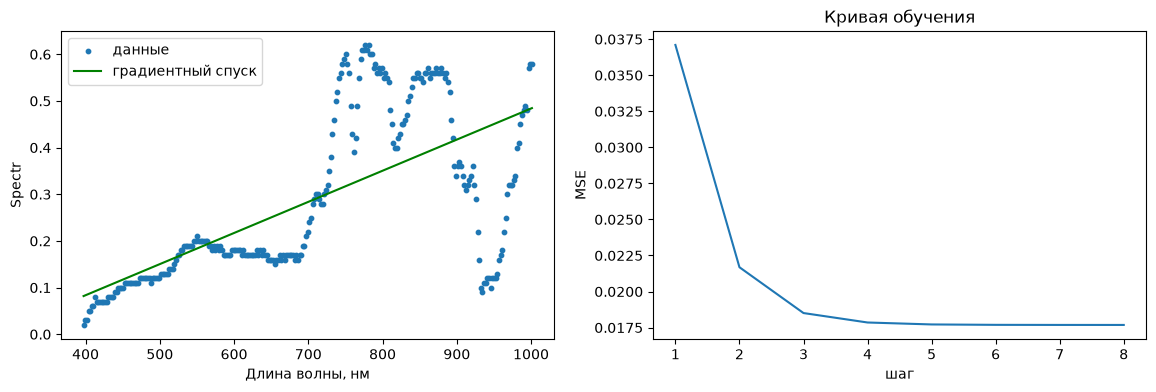

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(x, Y, s=10, label='данные')
ax[0].plot(x_space, gd.predict(x_space), 'g', label='градиентный спуск')
ax[0].set_xlabel('Длина волны, нм')
ax[0].set_ylabel('Spectr')
ax[0].legend()
ax[1].plot(steps, errors)
ax[1].set_xlabel('шаг')
ax[1].set_ylabel('MSE')
ax[1].set_title('Кривая обучения')
plt.show()

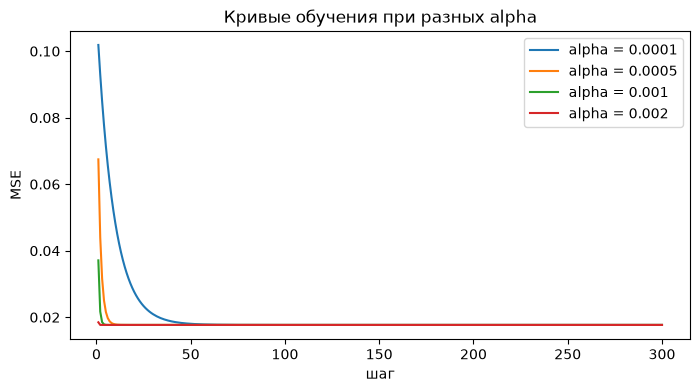

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
for alpha in [0.0001, 0.0005, 0.001, 0.002]:
    r = SimpleRegression()
    steps_a, errors_a = r.fit(z, Y, alpha=alpha, epsilon=0, max_steps=300)
    ax.plot(steps_a, errors_a, label=f'alpha = {alpha}')
ax.set_xlabel('шаг')
ax.set_ylabel('MSE')
ax.set_title('Кривые обучения при разных alpha')
ax.legend()
plt.show()

### 2.3. Оценка качества моделей

In [16]:
pd.DataFrame({
    'a0': [analytic.a0, gd.a0],
    'a1': [analytic.a1, gd.a1],
    'MSE': [analytic.MSE(x, Y), gd.MSE(x, Y)],
    'MAE': [analytic.MAE(x, Y), gd.MAE(x, Y)],
    'MAPE': [analytic.MAPE(x, Y), gd.MAPE(x, Y)],
    'R^2': [1 - analytic.MSE(x, Y) / Y.var(), 1 - gd.MSE(x, Y) / Y.var()],
}, index=['Аналитически', 'Градиентный спуск'])

,a0,a1,MSE,MAE,MAPE,R^2
Аналитически,-0.1834,0.0006682,0.01768,0.09683,0.4338,0.4359
Градиентный спуск,-0.1831,0.0006669,0.01768,0.09678,0.4326,0.4359


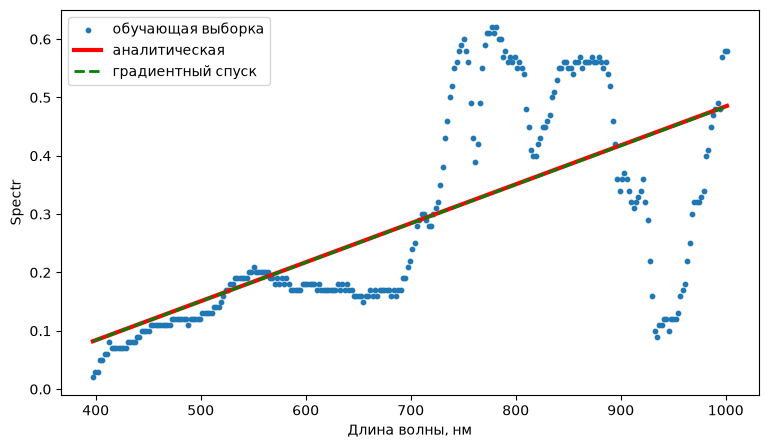

In [17]:
plt.figure(figsize=(9, 5))
plt.scatter(x, Y, s=10, label='обучающая выборка')
plt.plot(x_space, analytic.predict(x_space), 'r', lw=3, label='аналитическая')
plt.plot(x_space, gd.predict(x_space), 'g--', lw=2, label='градиентный спуск')
plt.xlabel('Длина волны, нм')
plt.ylabel('Spectr')
plt.legend()
plt.show()

### Выводы

1. Оценки градиентного спуска совпадают с аналитическими до 3–4 значащих цифр (прямые на графике накладываются): спуск сошёлся к решению МНК, остаточное расхождение определяется порогом `epsilon`.
2. Без масштабирования признака градиентный спуск на этих данных расходится; стандартизация $x$ решает проблему.
3. Качество линейной модели низкое: $R^2 \approx 0.44$, MAPE около 43 %. Спектр имеет нелинейную форму (почти плато в видимой части, резкий подъём около 700 нм — «красный край» растительности, затем высокий уровень и глубокий провал около 930–970 нм), и прямая описывает только общий тренд. Для этих данных лучше подойдёт нелинейная (например, полиномиальная) модель.